In [6]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuracion el estilo visual
sns.set_theme(style="whitegrid")

# 1. Descarga datos históricos de Tesla usando 'yf' , rango de un año desde el 14 de octubre de 2025 hasta el 14 de octubre de 2026
df = yf.download('TSLA', start='2025-10-14', end='2026-10-14')
display(df.head())
# Limpiar y aplanar columnas que vienen en formato multi-índice
df = df.reset_index()
df.columns = [col[0].lower() if isinstance(col, tuple) else col.lower() for col in df.columns]

# Mostrar primeras filas
display(df.head())

# 2. Guardar archivor en carpeta data/ de tu proyecto
df.to_csv('../data/tesla_data.csv', index=False)
print("¡Datos de Tesla descargados y guardados en data/tesla_data.csv con éxito!")

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,
2025-10-14,429.239990,434.200012,417.859985,426.790009,72669400
2025-10-15,435.149994,440.510010,426.329987,434.899994,71558200
2025-10-16,428.750000,439.350006,421.309998,434.730011,77189900
2025-10-17,439.309998,441.459991,423.600006,425.500000,89331600
2025-10-20,447.429993,449.799988,440.609985,443.869995,63719000


,date,close,high,low,open,volume
0,2025-10-14,429.239990,434.200012,417.859985,426.790009,72669400
1,2025-10-15,435.149994,440.510010,426.329987,434.899994,71558200
2,2025-10-16,428.750000,439.350006,421.309998,434.730011,77189900
3,2025-10-17,439.309998,441.459991,423.600006,425.500000,89331600
4,2025-10-20,447.429993,449.799988,440.609985,443.869995,63719000


¡Datos de Tesla descargados y guardados en data/tesla_data.csv con éxito!


,date,close,high,low,open,volume
0,2025-10-14,429.239990,434.200012,417.859985,426.790009,72669400
1,2025-10-15,435.149994,440.510010,426.329987,434.899994,71558200
2,2025-10-16,428.750000,439.350006,421.309998,434.730011,77189900
3,2025-10-17,439.309998,441.459991,423.600006,425.500000,89331600
4,2025-10-20,447.429993,449.799988,440.609985,443.869995,63719000


<class 'pandas.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    251 non-null    str    
 1   close   251 non-null    float64
 2   high    251 non-null    float64
 3   low     251 non-null    float64
 4   open    251 non-null    float64
 5   volume  251 non-null    int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 11.9 KB


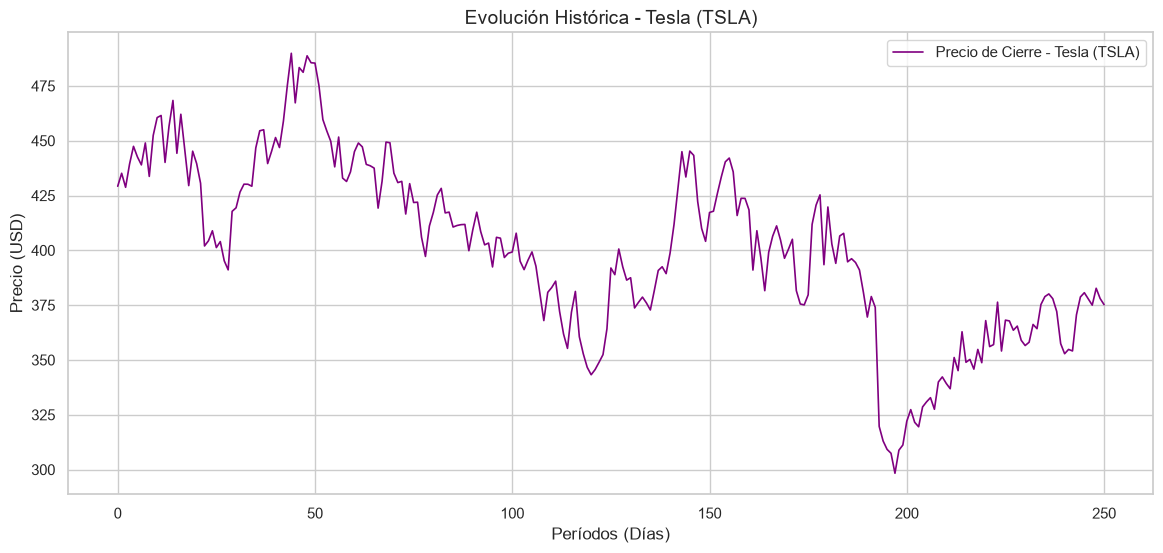

Total de registros: 251
-> Datos de Entrenamiento: 200
-> Datos de Evaluación (Held-out): 51
¡Conjuntos de entrenamiento y prueba de Tesla guardados con éxito!


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")

# 1. Cargar el dataset de Tesla desde la carpeta data/
df = pd.read_csv('../data/tesla_data.csv')

# Mostrar las primeras filas y estructura
display(df.head())
df.info()

# 2. Gráfica de la evolución histórica del precio de cierre (Close)
plt.figure(figsize=(14, 6))
plt.plot(df['close'], color='purple', linewidth=1.2, label='Precio de Cierre - Tesla (TSLA)')
plt.title('Evolución Histórica - Tesla (TSLA)', fontsize=14)
plt.xlabel('Períodos (Días)', fontsize=12)
plt.ylabel('Precio (USD)', fontsize=12)
plt.legend()
plt.show()

# 3. División cronológica (80% Entrenamiento / 20% Evaluación)
porcentaje_train = 0.8
corte = int(len(df) * porcentaje_train)

df_train = df.iloc[:corte].copy()
df_test = df.iloc[corte:].copy()

print(f"Total de registros: {len(df)}")
print(f"-> Datos de Entrenamiento: {len(df_train)}")
print(f"-> Datos de Evaluación (Held-out): {len(df_test)}")

# 4. Guardar los archivos segmentados para el entorno de Gymnasium
df_train.to_csv('../data/train_tesla.csv', index=False)
df_test.to_csv('../data/test_tesla.csv', index=False)
print("¡Conjuntos de entrenamiento y prueba de Tesla guardados con éxito!")

## Análisis exploratorio (justifica el estado)

Los CSV de `data/` ya existen. Esta parte **no reentrena el agente** ni vuelve a partir train/test: solo describe la serie.

**Por qué el estado es retorno + cash + posición (y no el precio crudo)**
- El *retorno de ayer* es adimensional y comparable entre días; el precio absoluto (~300–450 USD) no aporta una señal de decisión por sí solo.
- El *cash normalizado* dice cuánto efectivo queda para rebalancear.
- La *posición real* es necesaria: el costo de operar depende de *cambiar* 0 / 50 / 100 %.

No usamos RSI ni medias móviles en esta versión para mantener el MDP chico y defendible. El agente ve el retorno de **ayer** (lookahead-safe).

**Régimen:** el bloque de entrenamiento (primeros 80 %) es predominantemente *bajista*; el held-out (20 %) es *alcista*. Un agente que aprendió a protegerse en caída puede no subirse al rally de test. Eso no es un bug de código: es no-estacionariedad.

Registros: 251  |  train 200  |  test 51
Corte 80/20: 2026-08-03
Train  close 429.24 → 311.21  (-27.5%)
Test   close 322.08 → 375.23  (16.5%)
Retornos diarios (toda la serie):
mean   -0.0001
std     0.0283
min    -0.1452
max     0.0846
Name: ret, dtype: float64


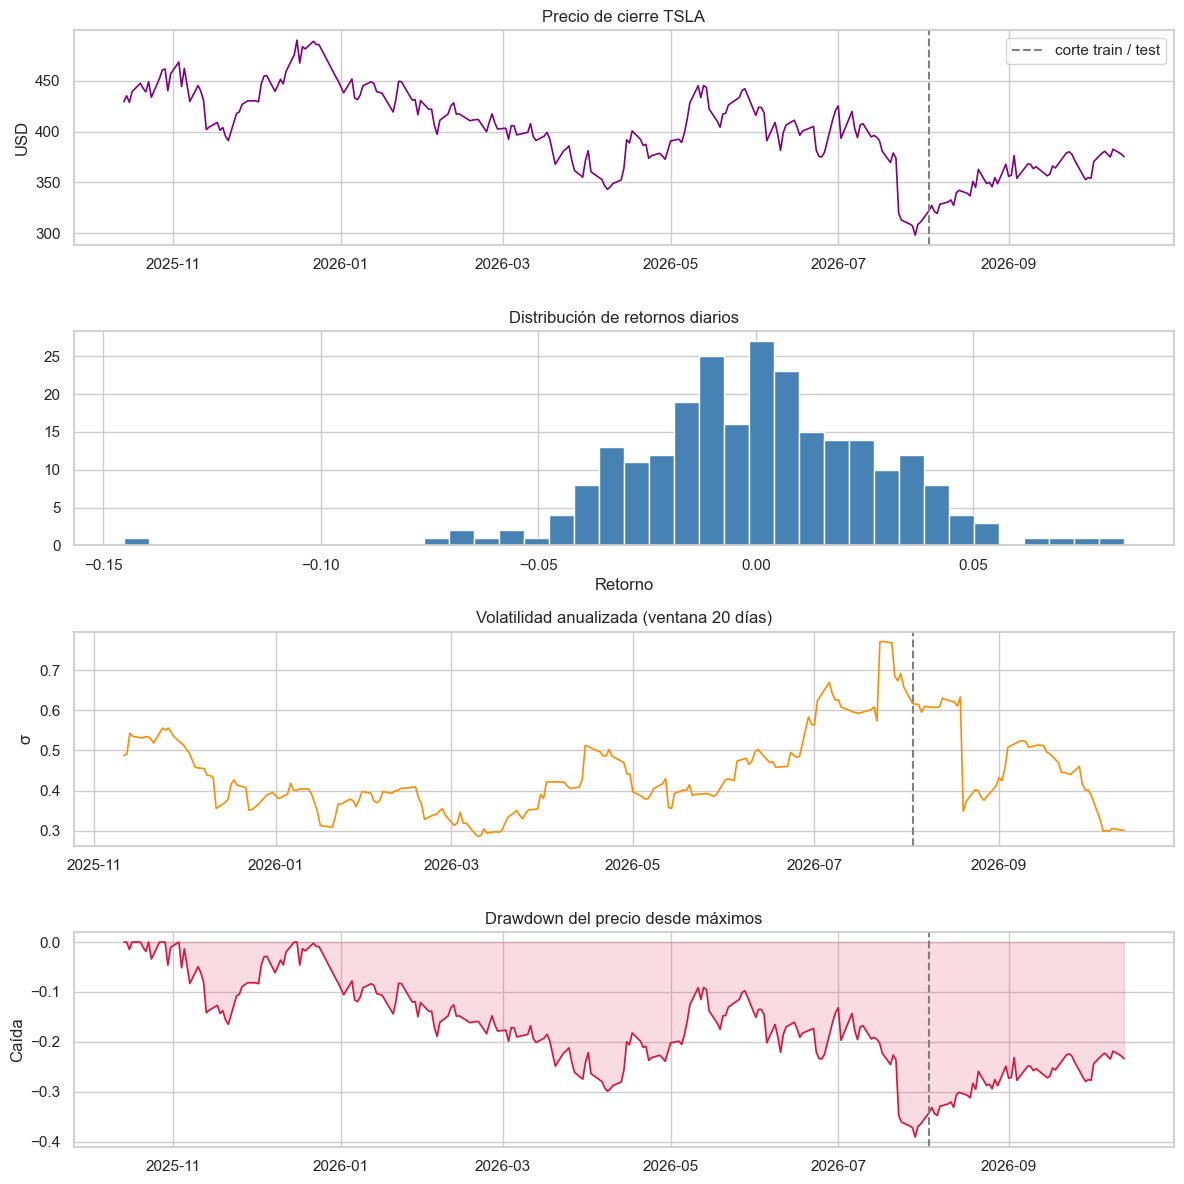

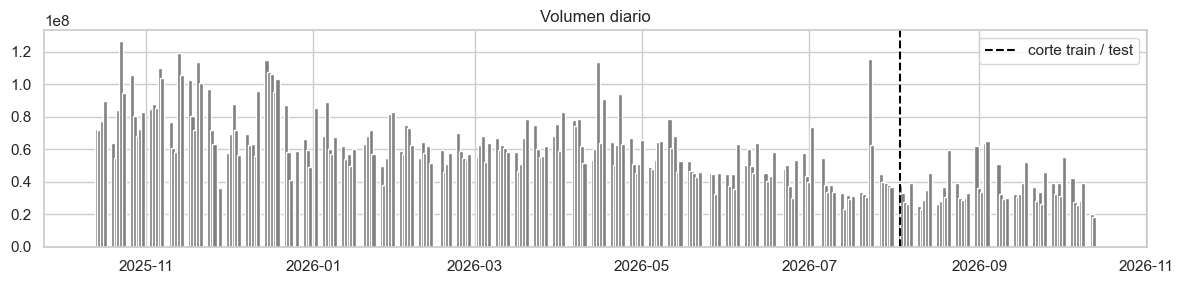

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Lee los datos ya guardados (no descarga ni resetea el split).
df = pd.read_csv("../data/tesla_data.csv", parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)
df["ret"] = df["close"].pct_change()
df["vol20"] = df["ret"].rolling(20).std() * np.sqrt(252)
peak = df["close"].cummax()
df["drawdown"] = df["close"] / peak - 1.0

corte = int(len(df) * 0.8)
fecha_corte = df.loc[corte, "date"]
train, test = df.iloc[:corte], df.iloc[corte:]

print(f"Registros: {len(df)}  |  train {len(train)}  |  test {len(test)}")
print(f"Corte 80/20: {fecha_corte.date()}")
print(f"Train  close {train['close'].iloc[0]:.2f} → {train['close'].iloc[-1]:.2f}  ({(train['close'].iloc[-1]/train['close'].iloc[0]-1)*100:.1f}%)")
print(f"Test   close {test['close'].iloc[0]:.2f} → {test['close'].iloc[-1]:.2f}  ({(test['close'].iloc[-1]/test['close'].iloc[0]-1)*100:.1f}%)")
print("Retornos diarios (toda la serie):")
print(df["ret"].describe()[["mean", "std", "min", "max"]].round(4))

fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=False)

axes[0].plot(df["date"], df["close"], color="purple", linewidth=1.2)
axes[0].axvline(fecha_corte, color="gray", linestyle="--", label="corte train / test")
axes[0].set_title("Precio de cierre TSLA")
axes[0].set_ylabel("USD")
axes[0].legend()

axes[1].hist(df["ret"].dropna(), bins=40, color="steelblue", edgecolor="white")
axes[1].set_title("Distribución de retornos diarios")
axes[1].set_xlabel("Retorno")

axes[2].plot(df["date"], df["vol20"], color="darkorange", linewidth=1.2)
axes[2].axvline(fecha_corte, color="gray", linestyle="--")
axes[2].set_title("Volatilidad anualizada (ventana 20 días)")
axes[2].set_ylabel("σ")

axes[3].plot(df["date"], df["drawdown"], color="crimson", linewidth=1.2)
axes[3].axvline(fecha_corte, color="gray", linestyle="--")
axes[3].fill_between(df["date"], df["drawdown"], 0, color="crimson", alpha=0.15)
axes[3].set_title("Drawdown del precio desde máximos")
axes[3].set_ylabel("Caída")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 3))
plt.bar(df["date"], df["volume"], color="gray", width=1.5)
plt.axvline(fecha_corte, color="black", linestyle="--", label="corte train / test")
plt.title("Volumen diario")
plt.legend()
plt.tight_layout()
plt.show()